In [2]:
# 1. 기본 데이터 처리 및 수치 연산
import pandas as pd
import numpy as np

# 2. 데이터 전처리 (스케일링 - PCA 수행 전 필수)
from sklearn.preprocessing import StandardScaler  # 표준 정규화 (평균 0, 분산 1)
from sklearn.preprocessing import MinMaxScaler    # 필요 시 최소-최대 정규화

# 3. PCA 모델링
from sklearn.decomposition import PCA             # 기본 PCA
from sklearn.decomposition import IncrementalPCA  # 대용량 데이터 배치 처리용
from sklearn.decomposition import KernelPCA       # 비선형 PCA
from sklearn.decomposition import SparsePCA       # 희소 주성분 분석

# 4. 시각화 (Scree Plot, 2D/3D 축소 결과 산점도)
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D           # 3차원 투영 시각화용

# 5. 모델 파이프라인 구성 및 사용할 데이터셋
from sklearn.pipeline import Pipeline
from sklearn.datasets import load_wine

In [9]:
# 1. 데이터셋 로드
wine = load_wine()

# [점검 1-1] Bunch 객체 속성 및 기본 메타데이터 확인
print("=== [1단계] Bunch 객체 기본 정보 ===")
print("Bunch Keys :", list(wine.keys()))
print("샘플 수 x 특성 수 :", wine.data.shape)
print("타깃 클래스 이름 :", wine.target_names)
print("클래스별 샘플 수 분포 :", np.bincount(wine.target))

# [점검 1-2] DataFrame 변환 후 특성별 기초 통계량(평균, 편차, 스케일 차이) 확인
df_raw = pd.DataFrame(data=wine.data, columns=wine.feature_names)
print("\n[특성별 기초 통계량 (요약)]")
print(df_raw.describe().T[['mean', 'std', 'min', 'max']].head())

# [점검 1-3] 결측치(NaN/Inf) 여부 검증
has_nan = np.isnan(wine.data).any()
print(f"\n결측치 존재 여부: {has_nan}")

=== [1단계] Bunch 객체 기본 정보 ===
Bunch Keys : ['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names']
샘플 수 x 특성 수 : (178, 13)
타깃 클래스 이름 : ['class_0' 'class_1' 'class_2']
클래스별 샘플 수 분포 : [59 71 48]

[특성별 기초 통계량 (요약)]
                        mean        std    min     max
alcohol            13.000618   0.811827  11.03   14.83
malic_acid          2.336348   1.117146   0.74    5.80
ash                 2.366517   0.274344   1.36    3.23
alcalinity_of_ash  19.494944   3.339564  10.60   30.00
magnesium          99.741573  14.282484  70.00  162.00

결측치 존재 여부: False


In [10]:
# 2. 표준 정규화 적용
scaler = StandardScaler()
X_scaled = scaler.fit_transform(wine.data)

# [점검 2-1] 스케일링 변환 검증 (평균 ≈ 0, 표준편차 ≈ 1)
print("=== [2단계] 스케일링 상태 검증 ===")
print("변환 후 특성별 평균 (최대 절댓값):", np.max(np.abs(X_scaled.mean(axis=0))))
print("변환 후 특성별 분산 (평균값):", np.mean(X_scaled.var(axis=0)))

# [점검 2-2] 공분산 행렬 계산 및 대칭성 확인
cov_matrix = np.cov(X_scaled, rowvar=False)
print(f"공분산 행렬 형태: {cov_matrix.shape}")
print(f"공분산 행렬 대칭성 만족 여부: {np.allclose(cov_matrix, cov_matrix.T)}")

=== [2단계] 스케일링 상태 검증 ===
변환 후 특성별 평균 (최대 절댓값): 7.841417902015432e-15
변환 후 특성별 분산 (평균값): 1.0
공분산 행렬 형태: (13, 13)
공분산 행렬 대칭성 만족 여부: True


=== [3단계] 주성분별 설명 분산 분석 ===
   주성분  고유값 (Eigenvalue)  개별 설명 분산 비율  누적 설명 분산 비율
0  PC1          4.732437     0.361988     0.361988
1  PC2          2.511081     0.192075     0.554063
2  PC3          1.454242     0.111236     0.665300
3  PC4          0.924166     0.070690     0.735990
4  PC5          0.858049     0.065633     0.801623
5  PC6          0.645282     0.049358     0.850981


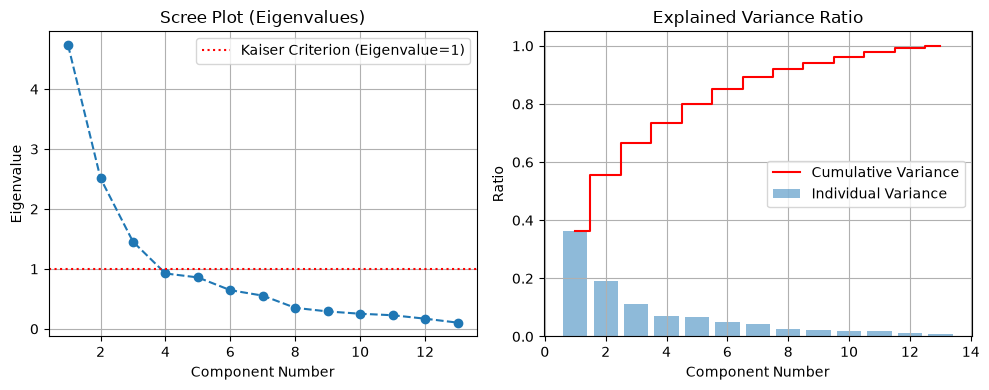

In [11]:
# 3. 전체 성분(13개)에 대한 PCA 적합
pca_full = PCA().fit(X_scaled)

# [점검 3-1] 주성분별 설명 분산(고유값) 및 분산 비율 확인
eigenvalues = pca_full.explained_variance_
var_ratio = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(var_ratio)

df_variance = pd.DataFrame({
    '주성분': [f'PC{i+1}' for i in range(len(eigenvalues))],
    '고유값 (Eigenvalue)': eigenvalues,
    '개별 설명 분산 비율': var_ratio,
    '누적 설명 분산 비율': cumulative_var
})
print("=== [3단계] 주성분별 설명 분산 분석 ===")
print(df_variance.head(6))

# [점검 3-2] Scree Plot 및 카이저 기준(Kaiser's Rule: 고유값 >= 1) 시각화
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', linestyle='--')
plt.axhline(y=1.0, color='r', linestyle=':', label='Kaiser Criterion (Eigenvalue=1)')
plt.title('Scree Plot (Eigenvalues)')
plt.xlabel('Component Number')
plt.ylabel('Eigenvalue')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(range(1, len(var_ratio) + 1), var_ratio, alpha=0.5, label='Individual Variance')
plt.step(range(1, len(cumulative_var) + 1), cumulative_var, where='mid', color='red', label='Cumulative Variance')
plt.title('Explained Variance Ratio')
plt.xlabel('Component Number')
plt.ylabel('Ratio')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
# 4. 상위 2개 성분으로 최종 차원 축소
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

# [점검 4-1] 고유벡터(Eigenvector) 크기(L2-norm = 1) 확인
eigenvectors = pca_2d.components_
norms = np.linalg.norm(eigenvectors, axis=1)
print("=== [4단계] 고유벡터 기하학적 특성 검증 ===")
print(f"각 고유벡터의 크기 (정규화 여부): {norms}")

# [점검 4-2] 주성분 축 간의 내적(Dot product ≈ 0, 직교성) 확인
dot_product = np.dot(eigenvectors[0], eigenvectors[1])
print(f"PC1과 PC2 벡터의 내적 (직교 여부): {dot_product:.1e}")

# [점검 4-3] 축소된 좌표계 간의 상관관계(공분산 = 0) 확인
corr_between_pcs = np.corrcoef(X_pca[:, 0], X_pca[:, 1])[0, 1]
print(f"변환된 PC1과 PC2 사이의 피어슨 상관계수: {corr_between_pcs:.1e}")

=== [4단계] 고유벡터 기하학적 특성 검증 ===
각 고유벡터의 크기 (정규화 여부): [1. 1.]
PC1과 PC2 벡터의 내적 (직교 여부): -2.5e-16
변환된 PC1과 PC2 사이의 피어슨 상관계수: -2.8e-16


=== [5단계] 특성별 기여도 및 복원 오차 ===

[상위 기여 특성 (PC1 기준 절대값 순)]
                              Loading_PC1  Loading_PC2
flavanoids                       0.920058    -0.005324
total_phenols                    0.858552     0.103064
od280/od315_of_diluted_wines     0.818321    -0.260667
proanthocyanins                  0.681840     0.062279
nonflavanoid_phenols            -0.649434     0.045605

평균 제곱 복원 오차 (Reconstruction MSE): 0.4459
이론상 손실된 분산 비율: 0.4459


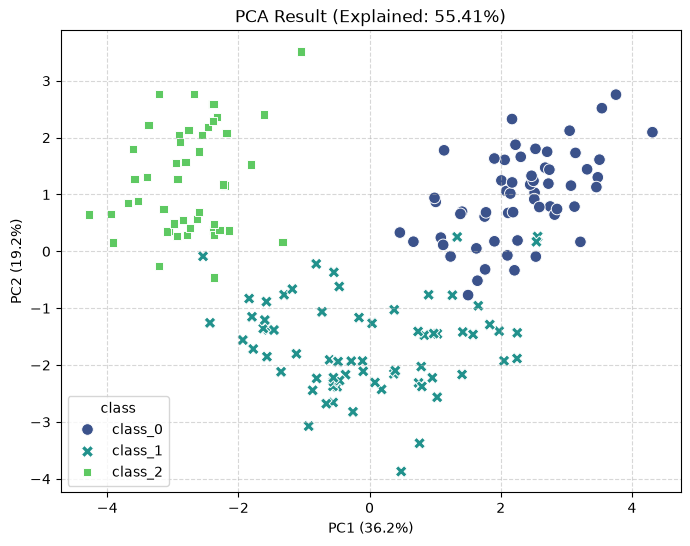

In [13]:
# [점검 5-1] 적재값(Factor Loading = Eigenvector * sqrt(Eigenvalue)) 확인
loadings = pca_2d.components_.T * np.sqrt(pca_2d.explained_variance_)
df_loadings = pd.DataFrame(loadings, index=wine.feature_names, columns=['Loading_PC1', 'Loading_PC2'])

print("=== [5단계] 특성별 기여도 및 복원 오차 ===")
print("\n[상위 기여 특성 (PC1 기준 절대값 순)]")
print(df_loadings.reindex(df_loadings['Loading_PC1'].abs().sort_values(ascending=False).index).head())

# [점검 5-2] 2차원 데이터를 원본 13차원으로 역변환(Inverse Transform) 후 복원 오차 계산
X_reconstructed = pca_2d.inverse_transform(X_pca)
recon_error = np.mean((X_scaled - X_reconstructed) ** 2)
print(f"\n평균 제곱 복원 오차 (Reconstruction MSE): {recon_error:.4f}")
print(f"이론상 손실된 분산 비율: {1 - np.sum(pca_2d.explained_variance_ratio_):.4f}")

# [점검 5-3] 최종 2D 시각화
df_result = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_result['target'] = wine.target
df_result['class'] = [wine.target_names[t] for t in wine.target]

plt.figure(figsize=(8, 6))
sns.scatterplot(x='PC1', y='PC2', hue='class', style='class', data=df_result, s=70, palette='viridis')
plt.title(f"PCA Result (Explained: {np.sum(pca_2d.explained_variance_ratio_)*100:.2f}%)")
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

13) 교차검증 K-Fold Cross Validation

- 교차검증은 데이터를 여러 부분으로 나누어 학습과 평가를 반복하고, 모델의 성능을 안정적으로 평가하는 방법이다.
- 교차검증은 모델 성능을 자동으로 높이는 방법이 아니라, 데이터 분할에 따른 우연한 결과의 영향을 줄이고 모델 성능을 더 신뢰성 있게 평가하는 방법이다.
- 교차검증 평균은 새로운 데이터에서의 실제 성능을 보장하는 값이 아니라, 홀드아웃(데이터를 한 번 나눠 훈련, 검증 또는 테스트)의 일반화 성능을 추정하는 값이다.

1. 교차검증을 하는 이유

단일 분할(Train/Test 1회) 방식은 테스트 데이터의 특성에 따라 성능 결과가 우연히 왜곡될 수 있어 모델의 진짜 일반화 성능을 확신할 수 없다. 교차검증은 전체 데이터를 여러 개(K개)의 폴드로 쪼개어 돌아가며 학습과 평가를 반복(모의고사 효과)한 뒤, 그 평균 성능을 확인함으로써 모델이 새로운 데이터에서도 안정적으로 일정한 성능을 발휘하는지 객관적으로 검증하기 위해서 수행한다.

| 목적 | 설명 | 확인 방법 |
|---|---|---|
| 모델 성능 평가 | 특정 검증 데이터에만 의존하지 않고 성능을 평가한다. | Fold별 점수와 평균 확인 |
| 모델 선택 | 여러 모델의 성능을 비교한다. | 모델별 교차검증 평균 비교 |
| 하이퍼파라미터 튜닝 | 모델 설정에 따른 성능 차이를 확인한다. | 설정값별 교차검증 점수 비교 |

2. K-Fold 교차검증
전체 데이터를 K개로 나누고, 각 부분을 한 번씩 검증 데이터로 사용한다. <br>

1) K-폴드 교차 검증(K-Fold Cross Validation)의 작동 원리 <br>
교차 검증이 필요한 이유 데이터 세트의 크기가 소규모일 때 고정된 검증 세트를 떼어내면 훈련 데이터 부족으로 모델 학습이 부실해진다. 교차 검증은 모든 데이터를 훈련 및 검증에 돌려가며 활용하므로, 데이터 손실을 방지하고 이상치/특이값에 대한 민감도를 크게 줄여 매우 안정적인 검증 점수를 확보할 수 있다. <br>
K-폴드 교차 검증은 마치 5번의 서로 다른 모의고사를 치러 평균 점수를 내는 수험생의 실력 평가와 같습니다. 단 한 번의 시험(단일 검증 세트)에서 발생할 수 있는 운이나 이상치의 영향을 최소화하는 것이다. <br>

​

2) K-폴드 교차 검증 순환 구조 <br>
테스트 세트를 제외한 나머지 데이터를 동일한 크기를 가진 K개의 조각(폴드)으로 나눈다. <br>
-> 첫 번째 폴드를 검증 세트로 지정하고, 나머지 (K-1)개 폴드로 모델을 훈련하여 첫 번째 검증 점수를 측정한다. <br>
-> 검증 세트 역할을 하는 폴드를 순차적으로 변경해 가며 총 K번의 학습과 검증을 반복한다. <br>
-> 각 회차에서 도출된 K개의 독립된 검증 평가 점수를 수집한다. <br>
-> K개의 검증 점수를 평균 내어 모델의 최종 대표 검증 점수로 활용한다. <br>

[ Fold 1 ] [ Fold 2 ] [ Fold 3 ] [ Fold 4 ] [ Fold 5 ] <br>
[ 검증 ] [ 훈련 ] [ 훈련 ] [ 훈련 ] [ 훈련 ] -> 1회차 평가 <br>
[ 훈련 ] [ 검증 ] [ 훈련 ] [ 훈련 ] [ 훈련 ] -> 2회차 평가 <br>
[ 훈련 ] [ 훈련 ] [ 검증 ] [ 훈련 ] [ 훈련 ] -> 3회차 평가 <br>
[ 훈련 ] [ 훈련 ] [ 훈련 ] [ 검증 ] [ 훈련 ] -> 4회차 평가 <br>
[ 훈련 ] [ 훈련 ] [ 훈련 ] [ 훈련 ] [ 검증 ] -> 5회차 평가 <br>
=> 5번 학습 5개 검증 점수의 평균 산출 <br>

3) 작업 형태(회귀 vs 분류)에 따른 분할기 선택

- 회귀 모델 (Regression): 기본 KFold 분할기를 사용
- 분류 모델 (Classification): StratifiedKFold 분할기를 사용
- 타깃 클래스의 비율이 각 폴드에 골고루 섞이지 않고 특정 폴드에 쏠리면 평가 결과가 왜곡됩니다. StratifiedKFold는 전체 타깃 클래스 비율을 각 폴드에 동일하게 유지해 줍니다.

​

4. 실습 <br>
[K-폴더 교차검증 실습 회귀] <br>
<br>
cross_val_score(estimator, X, y, cv, scoring) <br>
estimator : 각 분할에서 학습할 모델 <br>
X : 입력 데이터. 행은 샘플, 열은 특성 <br>
y : 정답 레이블 또는 예측 목표값. 비지도 학습처럼 필요하지 않은 경우 생략 <br>
cv : 데이터를 몇 조각으로 나누고 어떤 방식으로 분할할지 지정 <br>
scoring : 성능을 계산할 기준 <br>

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 데이터 불러오기
diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target

print(f"전체 샘플 개수: {len(X)}\n")

전체 샘플 개수: 442



In [3]:
# 1. 단일 홀드아웃 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_single = LinearRegression()
model_single.fit(X_train, y_train)

y_pred = model_single.predict(X_test)
single_mse = mean_squared_error(y_test, y_pred)
single_r2 = r2_score(y_test, y_pred)

print("=== 단일 홀드아웃 결과 ===")
print(f"테스트 MSE: {single_mse:.2f}")
print(f"테스트 R²:  {single_r2:.3f}\n")

=== 단일 홀드아웃 결과 ===
테스트 MSE: 2900.19
테스트 R²:  0.453



In [4]:
# 2. 전체 데이터에 K-Fold 적용
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
model_cv = LinearRegression()

mse_scores = cross_val_score(
    model_cv, X, y, cv=kfold, scoring="neg_mean_squared_error"
)
r2_scores = cross_val_score(
    model_cv, X, y, cv=kfold, scoring="r2"
)

cv_mse = -mse_scores

print("=== 전체 데이터 K-Fold 결과 ===")
print(f"각 폴드 MSE: {np.round(cv_mse, 2)}")
print(f"평균 MSE: {cv_mse.mean():.2f}")
print(f"각 폴드 R²: {np.round(r2_scores, 3)}")
print(f"평균 R²: {r2_scores.mean():.3f}")

=== 전체 데이터 K-Fold 결과 ===
각 폴드 MSE: [2900.19 2662.64 3312.31 2797.88 3403.89]
평균 MSE: 3015.38
각 폴드 R²: [0.453 0.573 0.391 0.584 0.391]
평균 R²: 0.478


[해석] Diabetes 회귀
- 홀드아웃 R²는 0.453, 전체 데이터 K-Fold 평균은 0.478로 비슷.
- K-Fold 폴드별 점수 차이가 있어, 분할에 따라 성능이 달라질 수 있다.
- MSE는 낮을수록 좋아.

In [5]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score
import numpy as np

# 데이터 불러오기
iris = load_iris()
X, y = iris.data, iris.target

print(f"전체 샘플 개수: {len(X)}\n")

전체 샘플 개수: 150



In [6]:
# 1. 단일 홀드아웃 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model_single = DecisionTreeClassifier(random_state=42)
model_single.fit(X_train, y_train)

y_pred = model_single.predict(X_test)
single_accuracy = accuracy_score(y_test, y_pred)

print("=== 단일 홀드아웃 결과 ===")
print(f"테스트 정확도: {single_accuracy * 100:.1f}%\n")

=== 단일 홀드아웃 결과 ===
테스트 정확도: 93.3%



In [ ]:
# 2. 전체 데이터에 Stratified K-Fold 적용
skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
a_scorss = 
model_cv = DecisionTreeClassifier(random_state=42)

cv_scores = cross_val_score(
    model_cv, X, y, cv=skfold, scoring="accuracy"
)

print("=== 전체 데이터 Stratified K-Fold 결과 ===")
print(f"각 폴드 정확도: {np.round(cv_scores * 100, 1)}%")
print(f"평균 정확도: {cv_scores.mean() * 100:.1f}%")

=== 전체 데이터 Stratified K-Fold 결과 ===
각 폴드 정확도: [100.   96.7  93.3  96.7  90. ]%
평균 정확도: 95.3%
